# Analyse exploratoire du panel fusionné (ARPD)
*Fedi Jouili — Eya Chaabouni*

Ce notebook se situe entre `01_data_merging.ipynb` (exploration de chaque source et fusion) et `final_panel.ipynb` (modèles de survie). Il décrit le **panel fusionné** (`data/processed/arpd_panel_merged.csv`) avec les mêmes définitions que les modèles, et justifie par des chiffres les choix de modélisation.

**Deux unités d'analyse, toujours précisées :**
* **par spell** : une ligne par parti au pouvoir (durée, événement, caractéristiques à l'entrée) ;
* **par parti-année** : une ligne par année au pouvoir (variables macro qui changent dans le temps).

Les durées sont **censurées** (une partie des partis est encore au pouvoir en fin d'observation) : les durées médianes sont donc estimées par Kaplan-Meier, jamais par la médiane brute des durées observées.

## Plan du notebook
0. Configuration & imports
1. Échantillon et définitions
2. Durées de survie (Kaplan-Meier)
3. Couverture des variables fusionnées
4. Les variables macro dans les années qui précèdent la chute
5. Contrôles qui motivent les choix de modélisation
6. Synthèse pour la modélisation

## 0. Configuration & imports

In [1]:
# ============================================================
# Configuration et imports
# ============================================================
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
from lifelines.utils import median_survival_times

RANDOM_STATE = 42
ALPHA = 0.05
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 100})

# Racine du projet : fonctionne que le notebook soit lancé depuis la racine ou depuis notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
assert (PROJECT_ROOT / "data").is_dir(), f"Racine du projet introuvable depuis {Path.cwd()}"
PANEL_PATH = PROJECT_ROOT / "data" / "processed" / "arpd_panel_merged.csv"
GRAPH_DIR = PROJECT_ROOT / "graph"     # figures préfixées « panel_ » (celles de 01_data_merging sont conservées)


def save(fig, name):
    fig.savefig(GRAPH_DIR / f"panel_{name}.png", dpi=150, bbox_inches="tight")


## 1. Échantillon et définitions

L'échantillon est celui de `final_panel.ipynb` : les **partis nommés** (`Party != "N"`), les juntes sans parti étant exclues. L'événement est la fin du spell au pouvoir (`event = 1 - Censored`, où `Censored = 1` signifie que le parti est encore au pouvoir en fin d'observation). Une version antérieure de ce notebook sélectionnait les partis par `regime_type_detail == "party"` : nous vérifions ci-dessous l'écart entre les deux définitions.

In [2]:
# ============================================================
# 1.1 Chargement et échantillon
# ============================================================
panel_all = pd.read_csv(PANEL_PATH, low_memory=False)
panel = panel_all[panel_all["Party"] != "N"].copy()
panel["spell_id"] = panel["Country"] + "_" + panel["Party"] + "_" + panel["Year in Power"].astype(str)
panel = panel.sort_values(["spell_id", "panel_year"]).reset_index(drop=True)
panel["log_gdppc"] = np.log(panel["gdppc_maddison"])

# Écart avec l'ancienne définition (regime_type_detail == "party")
old_def = panel_all["regime_type_detail"].eq("party")
new_def = panel_all["Party"].ne("N")
definition_check = pd.crosstab(new_def.rename("Party != N"), old_def.rename('regime_type_detail == "party"'))
display(definition_check)

# Mêmes regroupements que final_panel.ipynb (Section 3.1)
ORIGIN_MAP = {"Dictator-Created/Split": "Dictator-Created", "Dictator-Created/Merger": "Dictator-Created",
              "Merger": "Merger/Split", "Split": "Merger/Split"}
GOV_GROUPS = {"Policy-Based": "Policy-Based", "Policy-Based/Repressive": "Repressive", "Repressive": "Repressive",
              "Clientelist/Repressive": "Repressive", "Clientelist": "Clientelist",
              "Clientelist/Policy-Based": "Clientelist"}
panel["Origin_grp"] = panel["Origin"].replace(ORIGIN_MAP)
panel["Gov_grp"] = panel["Governance Strategy"].map(GOV_GROUPS).fillna("Non codé")

# Une ligne par spell : première et dernière ANNÉE du spell (pas groupby().first(), qui saute les valeurs manquantes)
first = panel.drop_duplicates("spell_id", keep="first").set_index("spell_id")
last = panel.drop_duplicates("spell_id", keep="last").set_index("spell_id")
ERAS = {"avant 1945": (-np.inf, 1944), "1945-1989": (1945, 1989), "depuis 1990": (1990, np.inf)}
spells = pd.DataFrame({
    "Country": first["Country"],
    "start_year": first["Year in Power"].astype(int),
    "end_year": last["panel_year"].astype(int),
    "duration": (last["panel_year"] - first["Year in Power"] + 1).astype(int),
    "event": (1 - first["Censored"]).astype(int),
    "Origin_grp": first["Origin_grp"],
    "Gov_grp": first["Gov_grp"],
    "Marxist": first["Marxist?"],
    "Monarchy": first["Monarchy"],
})
spells["era"] = pd.cut(spells["start_year"], [-np.inf, 1944, 1989, np.inf], labels=list(ERAS))
assert spells["duration"].min() >= 1

n_spells, n_events = len(spells), int(spells["event"].sum())
display(Markdown(
    f"**Échantillon.** {n_spells} spells de partis nommés (**par spell**), dont {n_events} chutes et "
    f"{n_spells - n_events} partis encore au pouvoir en {int(spells['end_year'].max())} "
    f"(taux de censure {(n_spells - n_events) / n_spells * 100:.1f} %), dans {spells['Country'].nunique()} pays, "
    f"soit {len(panel)} parti-années (**par parti-année**) de {int(panel['panel_year'].min())} à "
    f"{int(panel['panel_year'].max())}. Les deux définitions de l'échantillon diffèrent sur "
    f"{int((old_def != new_def).sum())} lignes du panel complet."
))


"regime_type_detail == ""party""",False,True
Party != N,,
False,2343,0
True,0,4766


**Échantillon.** 277 spells de partis nommés (**par spell**), dont 246 chutes et 31 partis encore au pouvoir en 2024 (taux de censure 11.2 %), dans 132 pays, soit 4766 parti-années (**par parti-année**) de 1878 à 2024. Les deux définitions de l'échantillon diffèrent sur 0 lignes du panel complet.

## 2. Durées de survie (Kaplan-Meier)

L'estimateur de Kaplan-Meier tient compte des partis encore au pouvoir (censure à droite). La durée médiane de survie est la durée à laquelle la courbe passe sous 50 % ; elle peut ne pas être atteinte si plus de la moitié d'un groupe est encore au pouvoir. Les différences entre groupes sont testées par le test du log-rank ($H_0$ : courbes de survie identiques). Toutes les statistiques de cette section sont **par spell**.

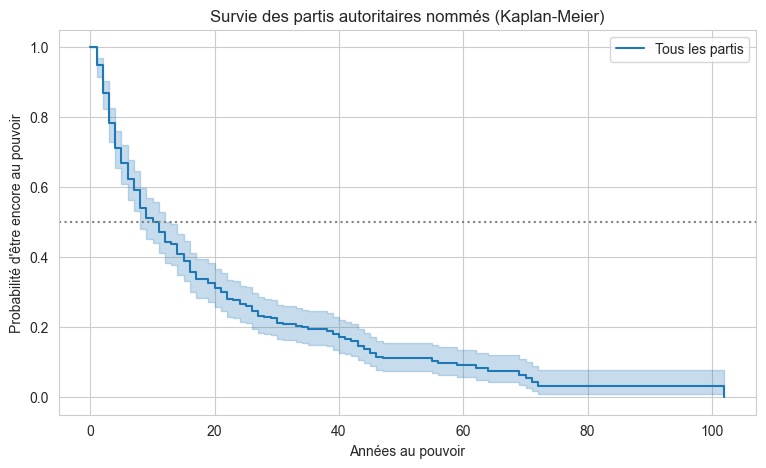

**Médiane de survie (Kaplan-Meier) : 11 ans** (IC 95 % : 8 – 13). La médiane brute des durées observées vaut 11 ans ; elle traite les 31 partis encore au pouvoir comme s'ils étaient tombés, ce qui ne peut que sous-estimer les durées. Ici, les deux médianes coïncident car la censure est faible, mais seule la médiane de Kaplan-Meier est correcte en général.

In [3]:
# ============================================================
# 2.1 Courbe de survie globale
# ============================================================
kmf = KaplanMeierFitter().fit(spells["duration"], spells["event"], label="Tous les partis")
median_ci = median_survival_times(kmf.confidence_interval_)
km_median, km_low, km_high = kmf.median_survival_time_, median_ci.iloc[0, 0], median_ci.iloc[0, 1]
raw_median = spells["duration"].median()

fig, ax = plt.subplots(figsize=(9, 5))
kmf.plot_survival_function(ax=ax)
ax.axhline(0.5, color="grey", linestyle=":")
ax.set_xlabel("Années au pouvoir")
ax.set_ylabel("Probabilité d'être encore au pouvoir")
ax.set_title("Survie des partis autoritaires nommés (Kaplan-Meier)")
save(fig, "km_global")
plt.show()

display(Markdown(
    f"**Médiane de survie (Kaplan-Meier) : {km_median:.0f} ans** (IC 95 % : {km_low:.0f} – {km_high:.0f}). "
    f"La médiane brute des durées observées vaut {raw_median:.0f} ans ; elle traite les {n_spells - n_events} partis "
    "encore au pouvoir comme s'ils étaient tombés, ce qui ne peut que sous-estimer les durées. "
    + ("Ici, l'écart est visible." if raw_median < km_median else
       "Ici, les deux médianes coïncident car la censure est faible, mais seule la médiane de Kaplan-Meier est "
       "correcte en général.")
))


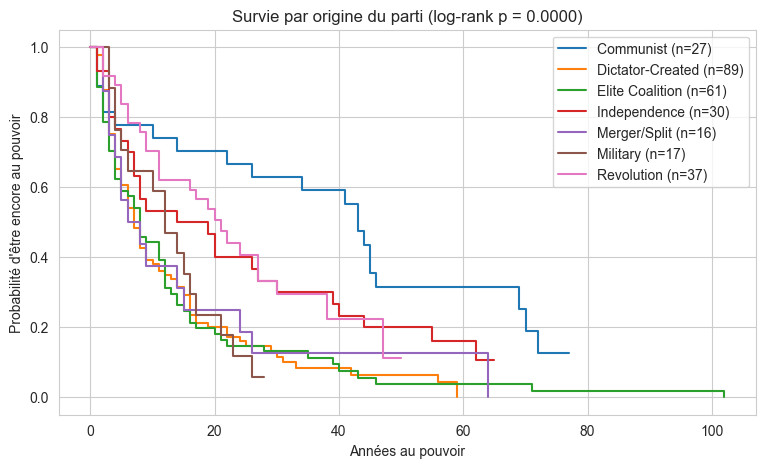

,spells,chutes,médiane KM (ans),IC bas,IC haut
Origin_grp,,,,,
Communist,27,21,43.0,14.0,46.0
Revolution,37,26,21.0,11.0,27.0
Independence,30,26,14.0,7.0,30.0
Military,17,16,12.0,4.0,17.0
Elite Coalition,61,60,8.0,4.0,12.0
Dictator-Created,89,82,7.0,5.0,9.0
Merger/Split,16,15,6.0,3.0,15.0


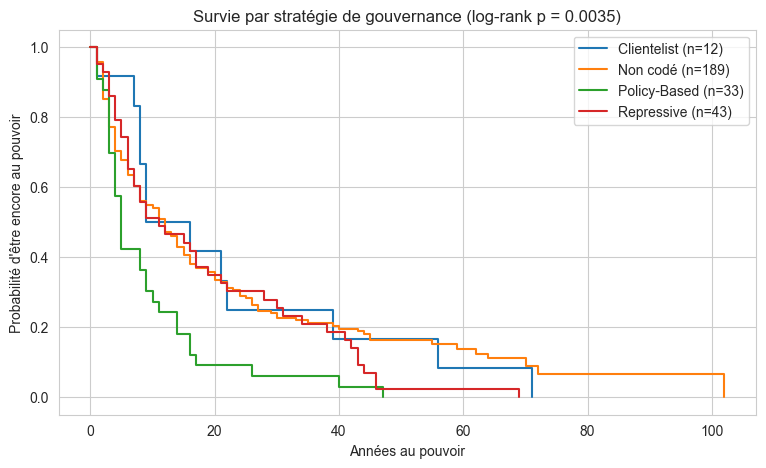

,spells,chutes,médiane KM (ans),IC bas,IC haut
Gov_grp,,,,,
Non codé,189,158,12.0,8.0,14.0
Repressive,43,43,11.0,6.0,19.0
Clientelist,12,12,9.0,7.0,39.0
Policy-Based,33,33,5.0,4.0,9.0


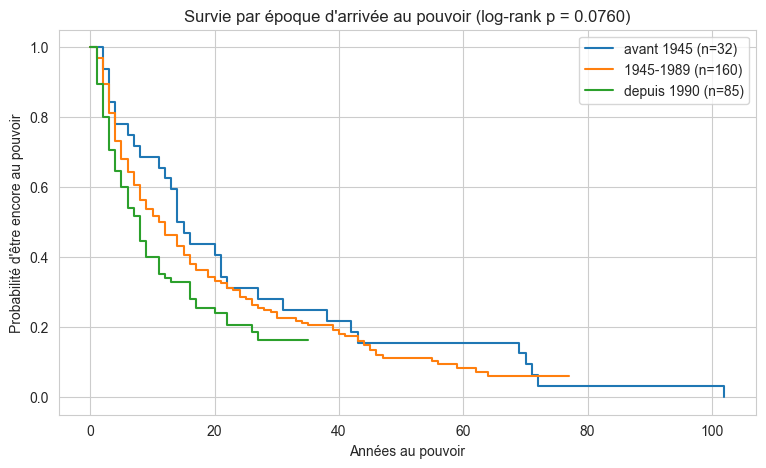

,spells,chutes,médiane KM (ans),IC bas,IC haut
era,,,,,
avant 1945,32,32,14.0,8.0,22.0
1945-1989,160,146,11.0,8.0,15.0
depuis 1990,85,68,8.0,5.0,11.0


- **Origine** : les courbes diffèrent significativement (log-rank p = 0.0000). Médiane la plus longue : Communist (43 ans) ; la plus courte : Merger/Split (6 ans).
- **Stratégie de gouvernance** : les courbes diffèrent significativement (log-rank p = 0.0035). Médiane la plus longue : Repressive (11 ans) ; la plus courte : Policy-Based (5 ans). La modalité « Non codé » (12 ans) n'est pas une stratégie et n'entre pas dans cette comparaison.
- **Époque d'arrivée au pouvoir** : les courbes ne diffèrent pas significativement (log-rank p = 0.0760). Médiane la plus longue : avant 1945 (14 ans) ; la plus courte : depuis 1990 (8 ans).

In [4]:
# ============================================================
# 2.2 Survie par origine, stratégie de gouvernance et époque d'arrivée au pouvoir
# ============================================================
def km_by(group_col, title, name):
    fig, ax = plt.subplots(figsize=(9, 5))
    rows = []
    for level, d in spells.groupby(group_col, observed=True):
        k = KaplanMeierFitter().fit(d["duration"], d["event"], label=f"{level} (n={len(d)})")
        k.plot_survival_function(ax=ax, ci_show=False)
        med = k.median_survival_time_
        ci = median_survival_times(k.confidence_interval_)
        rows.append({group_col: level, "spells": len(d), "chutes": int(d["event"].sum()),
                     "médiane KM (ans)": med, "IC bas": ci.iloc[0, 0], "IC haut": ci.iloc[0, 1]})
    test = multivariate_logrank_test(spells["duration"], spells[group_col].astype(str), spells["event"])
    ax.set_title(f"{title} (log-rank p = {test.p_value:.4f})")
    ax.set_xlabel("Années au pouvoir")
    ax.set_ylabel("Probabilité d'être encore au pouvoir")
    save(fig, name)
    plt.show()
    table = pd.DataFrame(rows).set_index(group_col).sort_values("médiane KM (ans)", ascending=False)
    display(table.replace(np.inf, np.nan).round(1))
    return table, test


tab_origin, test_origin = km_by("Origin_grp", "Survie par origine du parti", "km_origine")
tab_gov, test_gov = km_by("Gov_grp", "Survie par stratégie de gouvernance", "km_gouvernance")
tab_era, test_era = km_by("era", "Survie par époque d'arrivée au pouvoir", "km_epoque")


def describe_groups(table, test, label, not_a_group=()):
    finite = table[np.isfinite(table["médiane KM (ans)"]) & ~table.index.isin(not_a_group)]
    longest, shortest = finite.index[0], finite.index[-1]
    not_reached = table.index[~np.isfinite(table["médiane KM (ans)"])].tolist()
    verdict = "diffèrent significativement" if test.p_value < ALPHA else "ne diffèrent pas significativement"
    txt = (f"- **{label}** : les courbes {verdict} (log-rank p = {test.p_value:.4f}). Médiane la plus longue : "
           f"{longest} ({finite.loc[longest, 'médiane KM (ans)']:.0f} ans) ; la plus courte : {shortest} "
           f"({finite.loc[shortest, 'médiane KM (ans)']:.0f} ans).")
    if not_reached:
        txt += f" Médiane non atteinte (plus de la moitié encore au pouvoir) : {', '.join(map(str, not_reached))}."
    for level in not_a_group:
        if level in table.index:
            txt += (f" La modalité « {level} » ({table.loc[level, 'médiane KM (ans)']:.0f} ans) n'est pas une stratégie "
                    "et n'entre pas dans cette comparaison.")
    return txt


display(Markdown("\n".join([describe_groups(tab_origin, test_origin, "Origine"),
                             describe_groups(tab_gov, test_gov, "Stratégie de gouvernance", not_a_group=["Non codé"]),
                             describe_groups(tab_era, test_era, "Époque d'arrivée au pouvoir")])))


## 3. Couverture des variables fusionnées

Part des parti-années (**par parti-année**) pour lesquelles chaque source fusionnée fournit une valeur, année par année. Les trous de couverture déterminent la façon dont les variables macro entrent dans les modèles (entrée tardive dans le modèle time-varying, spells exclus du modèle statique).

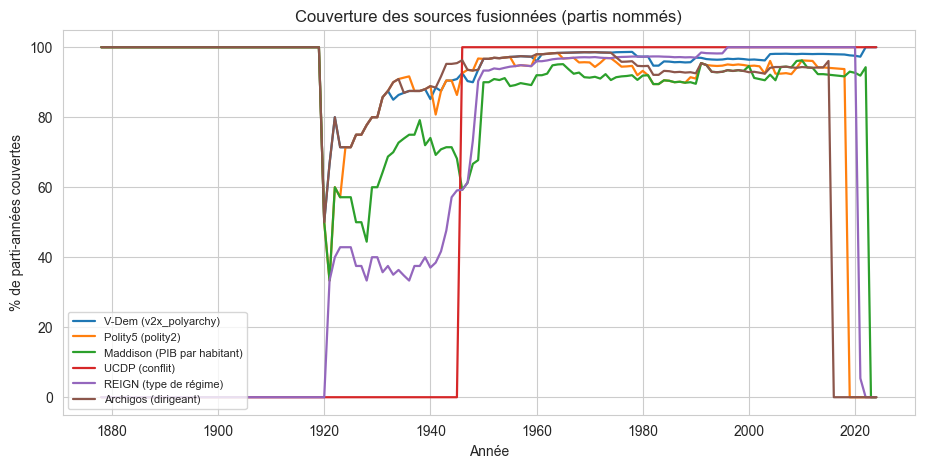

,couverture totale (%),première année,dernière année
V-Dem (v2x_polyarchy),96.3,1878,2024
Polity5 (polity2),89.2,1878,2018
Maddison (PIB par habitant),88.1,1878,2022
UCDP (conflit),90.5,1946,2024
REIGN (type de régime),88.6,1921,2021
Archigos (dirigeant),87.2,1878,2015


**Lecture.** V-Dem (v2x_polyarchy) : 96.3 % des parti-années, de 1878 à 2024 ; Polity5 (polity2) : 89.2 % des parti-années, de 1878 à 2018 ; Maddison (PIB par habitant) : 88.1 % des parti-années, de 1878 à 2022 ; UCDP (conflit) : 90.5 % des parti-années, de 1946 à 2024 ; REIGN (type de régime) : 88.6 % des parti-années, de 1921 à 2021 ; Archigos (dirigeant) : 87.2 % des parti-années, de 1878 à 2015.

In [5]:
# ============================================================
# 3.1 Couverture des sources par année
# ============================================================
SOURCES = {"V-Dem (v2x_polyarchy)": "v2x_polyarchy", "Polity5 (polity2)": "polity2",
           "Maddison (PIB par habitant)": "gdppc_maddison", "UCDP (conflit)": "conflict_active",
           "REIGN (type de régime)": "gwf_regimetype", "Archigos (dirigeant)": "entry"}
coverage_year = pd.DataFrame({name: panel.groupby("panel_year")[col].apply(lambda s: s.notna().mean() * 100)
                              for name, col in SOURCES.items()})
fig, ax = plt.subplots(figsize=(11, 5))
coverage_year.plot(ax=ax, lw=1.6)
ax.set_ylabel("% de parti-années couvertes")
ax.set_xlabel("Année")
ax.set_title("Couverture des sources fusionnées (partis nommés)")
ax.legend(fontsize=8, loc="lower left")
save(fig, "couverture")
plt.show()

first_year = {name: int(panel.loc[panel[col].notna(), "panel_year"].min()) for name, col in SOURCES.items()}
last_year = {name: int(panel.loc[panel[col].notna(), "panel_year"].max()) for name, col in SOURCES.items()}
coverage_table = pd.DataFrame({
    "couverture totale (%)": {name: panel[col].notna().mean() * 100 for name, col in SOURCES.items()},
    "première année": first_year, "dernière année": last_year,
})
display(coverage_table.round(1))
display(Markdown(
    "**Lecture.** " + " ; ".join(f"{name} : {row['couverture totale (%)']:.1f} % des parti-années, de "
                                 f"{int(row['première année'])} à {int(row['dernière année'])}"
                                 for name, row in coverage_table.iterrows()) + "."
))


## 4. Les variables macro dans les années qui précèdent la chute

Pour les spells qui se terminent, nous alignons les parti-années sur l'année de la chute (année 0) et calculons la moyenne de chaque variable de -10 à 0 ans. Pour comparaison, les spells encore au pouvoir sont alignés sur leur dernière année observée. Ces moyennes sont **par parti-année** et purement descriptives : elles ne contrôlent pas les autres variables. Elles montrent aussi pourquoi les modèles utilisent la valeur de l'**année précédente** : la valeur de l'année même de la chute peut déjà refléter la transition.

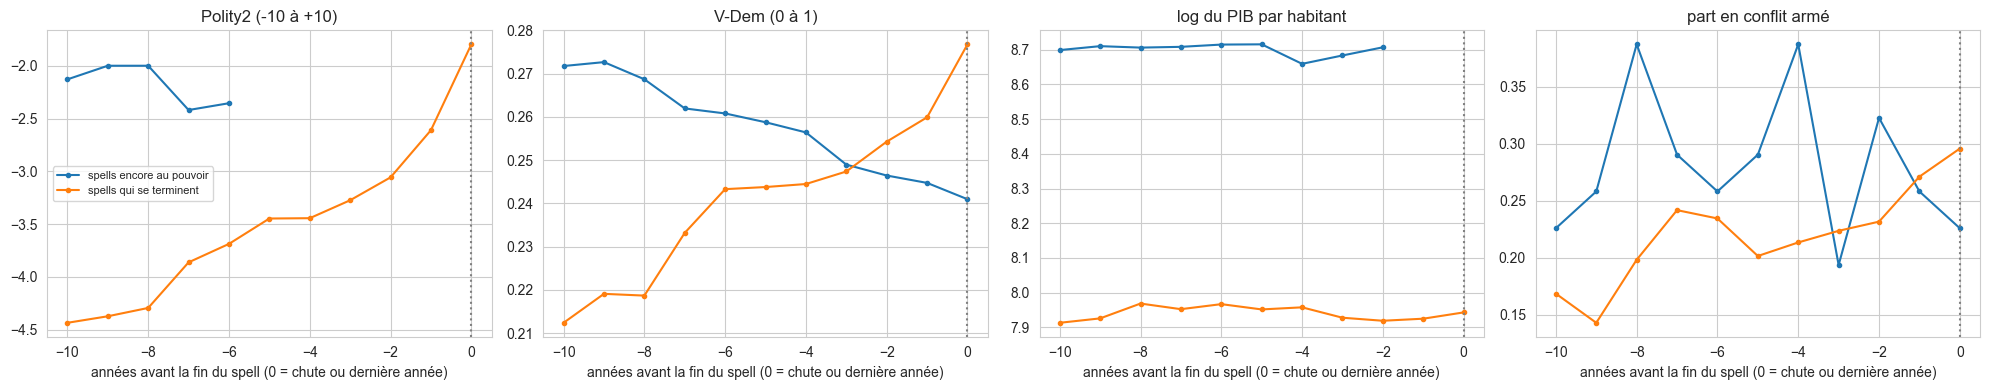

- **Polity2 (-10 à +10)** : pour les spells qui se terminent, -4.43 dix ans avant, -2.61 l'année précédant la chute et -1.80 l'année de la chute ; pour les spells encore au pouvoir, -2.13 puis non disponible.
- **V-Dem (0 à 1)** : pour les spells qui se terminent, 0.21 dix ans avant, 0.26 l'année précédant la chute et 0.28 l'année de la chute ; pour les spells encore au pouvoir, 0.27 puis 0.24.
- **log du PIB par habitant** : pour les spells qui se terminent, 7.91 dix ans avant, 7.93 l'année précédant la chute et 7.94 l'année de la chute ; pour les spells encore au pouvoir, 8.70 puis non disponible.
- **part en conflit armé** : pour les spells qui se terminent, 0.17 dix ans avant, 0.27 l'année précédant la chute et 0.30 l'année de la chute ; pour les spells encore au pouvoir, 0.23 puis 0.23.

Pour les spells encore au pouvoir, alignés sur leur dernière année observée (2024), Polity2 n'est pas disponible (Polity5 s'arrête en 2018) ni le PIB Maddison (dernière année 2022).

Entre l'année précédant la chute et l'année de la chute, l'indice V-Dem moyen varie de +0.017, contre +0.005 par an en moyenne sur les années précédentes : la valeur de l'année de la chute reflète déjà en partie la transition, ce qui justifie le retard d'un an des modèles time-varying.

In [6]:
# ============================================================
# 4.1 Profils avant la chute (event-time)
# ============================================================
WINDOW = 10
MACRO = {"polity2": "Polity2 (-10 à +10)", "v2x_polyarchy": "V-Dem (0 à 1)",
         "log_gdppc": "log du PIB par habitant", "conflict_active": "part en conflit armé"}
aligned = panel.merge(spells[["end_year", "event"]], left_on="spell_id", right_index=True)
aligned["t"] = aligned["panel_year"] - aligned["end_year"]
aligned = aligned[aligned["t"].between(-WINDOW, 0)]
aligned["groupe"] = np.where(aligned["event"] == 1, "spells qui se terminent", "spells encore au pouvoir")
profiles = aligned.groupby(["groupe", "t"])[list(MACRO)].mean()

fig, axes = plt.subplots(1, len(MACRO), figsize=(5 * len(MACRO), 4))
for ax, (var, label) in zip(axes, MACRO.items()):
    for group in profiles.index.get_level_values(0).unique():
        p = profiles.loc[group, var]
        ax.plot(p.index, p.values, marker="o", ms=3, label=group)
    ax.axvline(0, color="grey", linestyle=":")
    ax.set_title(label)
    ax.set_xlabel("années avant la fin du spell (0 = chute ou dernière année)")
axes[0].legend(fontsize=8)
save(fig, "avant_chute")
plt.tight_layout()
plt.show()

falls = profiles.loc["spells qui se terminent"]
alive = profiles.loc["spells encore au pouvoir"]
def value(x):
    return f"{x:.2f}" if pd.notna(x) else "non disponible"


last_available = {"polity2": int(panel.loc[panel["polity2"].notna(), "panel_year"].max()),
                  "gdppc_maddison": int(panel.loc[panel["gdppc_maddison"].notna(), "panel_year"].max())}
lines = []
for var, label in MACRO.items():
    lines.append(f"- **{label}** : pour les spells qui se terminent, {falls.loc[-WINDOW, var]:.2f} dix ans avant, "
                 f"{falls.loc[-1, var]:.2f} l'année précédant la chute et {falls.loc[0, var]:.2f} l'année de la chute ; "
                 f"pour les spells encore au pouvoir, {value(alive.loc[-WINDOW, var])} puis {value(alive.loc[0, var])}.")
jump_v = falls.loc[0, "v2x_polyarchy"] - falls.loc[-1, "v2x_polyarchy"]
trend_v = (falls.loc[-1, "v2x_polyarchy"] - falls.loc[-WINDOW, "v2x_polyarchy"]) / (WINDOW - 1)
display(Markdown(
    "\n".join(lines) + "\n\n"
    f"Pour les spells encore au pouvoir, alignés sur leur dernière année observée ({int(spells['end_year'].max())}), "
    f"Polity2 n'est pas disponible (Polity5 s'arrête en {last_available['polity2']}) ni le PIB Maddison (dernière "
    f"année {last_available['gdppc_maddison']}).\n\n"
    f"Entre l'année précédant la chute et l'année de la chute, l'indice V-Dem moyen varie de {jump_v:+.3f}, contre "
    f"{trend_v:+.3f} par an en moyenne sur les années précédentes : la valeur de l'année de la chute "
    f"{'reflète déjà en partie la transition, ce qui justifie le retard d un an des modèles time-varying' if abs(jump_v) > 2 * abs(trend_v) else 'ne s écarte pas nettement de la tendance des années précédentes'}."
    .replace("d un an", "d'un an").replace("s écarte", "s'écarte")
))


## 5. Contrôles qui motivent les choix de modélisation

Quatre vérifications chiffrées, chacune liée à un choix de `final_panel.ipynb` : le recouvrement entre origine communiste et idéologie marxiste, le lien entre Polity2 et V-Dem, le taux de codage de la stratégie de gouvernance, et la structure des valeurs manquantes des variables macro. Nous vérifions aussi pourquoi les variables `Military`, `Violence` et `Occupation` ne sont pas utilisées pour les partis nommés.

In [7]:
# ============================================================
# 5.1 Contrôles chiffrés
# ============================================================
# Origine communiste et idéologie marxiste (par spell)
communist = spells[spells["Origin_grp"] == "Communist"]
pct_marx_communist = communist["Marxist"].mean() * 100
pct_marx_other = spells.loc[spells["Origin_grp"] != "Communist", "Marxist"].mean() * 100

# Polity2 et V-Dem (par parti-année)
both = panel[["polity2", "v2x_polyarchy"]].dropna()
r_polity_vdem = both["polity2"].corr(both["v2x_polyarchy"])

# Codage de la stratégie de gouvernance (par spell)
gov_coded_pct = (spells["Gov_grp"] != "Non codé").mean() * 100
gov_by_origin = (spells.assign(code=spells["Gov_grp"] != "Non codé").groupby("Origin_grp")["code"].mean() * 100)

# Valeurs manquantes des variables macro (par parti-année), par époque
macro_cols = ["polity2", "v2x_polyarchy", "gdppc_maddison", "conflict_active"]
panel_era = pd.cut(panel["panel_year"], [-np.inf, 1945, 1959, 2018, np.inf],
                   labels=["avant 1946", "1946-1959", "1960-2018", "après 2018"])
missing_by_era = panel.groupby(panel_era, observed=True)[macro_cols].apply(lambda d: d.isna().mean() * 100)
all_three = panel[["polity2", "gdppc_maddison", "conflict_active"]].notna().all(axis=1).mean() * 100
display(Markdown("**Valeurs manquantes des variables macro (% des parti-années), par période :**"))
display(missing_by_era.round(1))

# Variables propres aux juntes (par parti-année, partis nommés)
junta_only = {v: sorted(panel[v].dropna().unique().tolist()) for v in ["Military", "Violence", "Occupation"]}
display(pd.DataFrame({"valeurs observées (partis nommés)": junta_only}))

display(Markdown(
    f"- **Origine et idéologie** : {pct_marx_communist:.0f} % des partis d'origine communiste sont codés "
    f"marxistes-léninistes, contre {pct_marx_other:.0f} % des autres partis (par spell) : les deux variables portent "
    "largement la même information, ce qui rend difficile d'isoler un effet propre de l'idéologie.\n"
    f"- **Polity2 et V-Dem** : corrélation de {r_polity_vdem:.2f} sur {len(both)} parti-années où les deux existent "
    "(par parti-année).\n"
    f"- **Stratégie de gouvernance** : codée pour {gov_coded_pct:.0f} % des spells seulement, avec un taux de codage "
    f"qui varie selon l'origine (de {gov_by_origin.min():.0f} % à {gov_by_origin.max():.0f} %) : les valeurs "
    "manquantes ne sont pas aléatoires.\n"
    f"- **Valeurs manquantes macro** : Polity2, le PIB Maddison et le conflit sont disponibles ensemble pour "
    f"{all_three:.0f} % des parti-années ; le conflit manque entièrement avant 1946 "
    f"({missing_by_era.loc['avant 1946', 'conflict_active']:.0f} % de valeurs manquantes) et Polity2 après 2018 "
    f"({missing_by_era.loc['après 2018', 'polity2']:.0f} %).\n"
    f"- **Variables propres aux juntes** : pour les partis nommés, `Military` ne prend que la valeur "
    f"{junta_only['Military']} ; dans l'ARPD, `Military`, `Violence` et `Occupation` décrivent les régimes sans parti "
    "(juntes), et leurs valeurs pour les partis nommés sont reconstruites par des règles : elles ne sont pas utilisées "
    "comme covariables."
))


**Valeurs manquantes des variables macro (% des parti-années), par période :**

,polity2,v2x_polyarchy,gdppc_maddison,conflict_active
panel_year,,,,
avant 1946,13.5,13.3,28.4,100.0
1946-1959,4.5,4.3,16.8,0.0
1960-2018,5.8,2.6,7.8,0.0
après 2018,100.0,1.3,35.0,0.0


,valeurs observées (partis nommés)
Military,[0.0]
Violence,"[0.0, 1.0]"
Occupation,[0.0]


- **Origine et idéologie** : 100 % des partis d'origine communiste sont codés marxistes-léninistes, contre 16 % des autres partis (par spell) : les deux variables portent largement la même information, ce qui rend difficile d'isoler un effet propre de l'idéologie.
- **Polity2 et V-Dem** : corrélation de 0.70 sur 4233 parti-années où les deux existent (par parti-année).
- **Stratégie de gouvernance** : codée pour 32 % des spells seulement, avec un taux de codage qui varie selon l'origine (de 17 % à 47 %) : les valeurs manquantes ne sont pas aléatoires.
- **Valeurs manquantes macro** : Polity2, le PIB Maddison et le conflit sont disponibles ensemble pour 76 % des parti-années ; le conflit manque entièrement avant 1946 (100 % de valeurs manquantes) et Polity2 après 2018 (100 %).
- **Variables propres aux juntes** : pour les partis nommés, `Military` ne prend que la valeur [0.0] ; dans l'ARPD, `Military`, `Violence` et `Occupation` décrivent les régimes sans parti (juntes), et leurs valeurs pour les partis nommés sont reconstruites par des règles : elles ne sont pas utilisées comme covariables.

## 6. Synthèse pour la modélisation

In [8]:
# ============================================================
# 6. Synthèse pour la modélisation (générée à partir des résultats)
# ============================================================
synthesis = [
    f"**Censure** : {n_spells - n_events} spells sur {n_spells} sont censurés ; la médiane de survie (Kaplan-Meier) "
    f"est de {km_median:.0f} ans ({raw_median:.0f} ans en médiane brute, qui ignore la censure) → modèles de survie "
    "(Cox), qui traitent la censure, plutôt qu'une régression sur les durées observées.",
    f"**Origine** : les courbes de survie diffèrent selon l'origine (log-rank p = {test_origin.p_value:.4f}) → "
    "l'origine est la covariable centrale des modèles, avec `Dictator-Created` (le groupe le plus nombreux) comme "
    "référence et les modalités rares regroupées.",
    f"**Stratégie de gouvernance** : codée pour {gov_coded_pct:.0f} % des spells, de façon non aléatoire → pas "
    "d'imputation à partir de l'origine ; modalité explicite « Non codé », interprétée comme une différence entre "
    "partis codés et non codés, pas comme une stratégie.",
    f"**Idéologie** : {pct_marx_communist:.0f} % des partis d'origine communiste sont marxistes-léninistes → l'effet "
    "de l'idéologie se lit avec prudence, une fois l'origine contrôlée.",
    f"**Niveau démocratique** : Polity2 et V-Dem sont corrélés à {r_polity_vdem:.2f}, mais Polity2 s'arrête en "
    f"{last_year['Polity5 (polity2)']} → Polity2 dans les modèles principaux, V-Dem en test de robustesse "
    "(`final_panel.ipynb`, Section 5.4).",
    f"**Variables macro** : couverture incomplète (conflit absent avant {first_year['UCDP (conflit)']}, PIB "
    f"Maddison disponible pour {coverage_table.loc['Maddison (PIB par habitant)', 'couverture totale (%)']:.0f} % des "
    "parti-années) → valeurs de la première année dans le modèle statique (sans remplacement par une année "
    "ultérieure), valeurs de l'année précédente et entrée tardive dans le modèle time-varying.",
    "**Variables propres aux juntes** (`Military`, `Violence`, `Occupation`) → non utilisées pour les partis nommés ; "
    "`Monarchy` est un codage propre.",
]
display(Markdown("\n".join(f"{i}. {s}" for i, s in enumerate(synthesis, start=1))))


1. **Censure** : 31 spells sur 277 sont censurés ; la médiane de survie (Kaplan-Meier) est de 11 ans (11 ans en médiane brute, qui ignore la censure) → modèles de survie (Cox), qui traitent la censure, plutôt qu'une régression sur les durées observées.
2. **Origine** : les courbes de survie diffèrent selon l'origine (log-rank p = 0.0000) → l'origine est la covariable centrale des modèles, avec `Dictator-Created` (le groupe le plus nombreux) comme référence et les modalités rares regroupées.
3. **Stratégie de gouvernance** : codée pour 32 % des spells, de façon non aléatoire → pas d'imputation à partir de l'origine ; modalité explicite « Non codé », interprétée comme une différence entre partis codés et non codés, pas comme une stratégie.
4. **Idéologie** : 100 % des partis d'origine communiste sont marxistes-léninistes → l'effet de l'idéologie se lit avec prudence, une fois l'origine contrôlée.
5. **Niveau démocratique** : Polity2 et V-Dem sont corrélés à 0.70, mais Polity2 s'arrête en 2018 → Polity2 dans les modèles principaux, V-Dem en test de robustesse (`final_panel.ipynb`, Section 5.4).
6. **Variables macro** : couverture incomplète (conflit absent avant 1946, PIB Maddison disponible pour 88 % des parti-années) → valeurs de la première année dans le modèle statique (sans remplacement par une année ultérieure), valeurs de l'année précédente et entrée tardive dans le modèle time-varying.
7. **Variables propres aux juntes** (`Military`, `Violence`, `Occupation`) → non utilisées pour les partis nommés ; `Monarchy` est un codage propre.